In [1]:
import io
import urllib.request
import zipfile
import pandas as pd

# 1. Fetch and load the UCI Bike Sharing Dataset directly into memory
url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})

with urllib.request.urlopen(req) as resp:
    with zipfile.ZipFile(io.BytesIO(resp.read())) as archive:
        with archive.open("hour.csv") as file:
            df = pd.read_csv(file)

# --- 1. Dataset Preview ---
print(" 1. DATASET PREVIEW")
display(df.head(-5))

# --- 2. Dataset Shape ---
print("\n 2. DATASET SHAPE")
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")

# --- 3. Columns List ---
print("\n 3. DATASET COLUMNS")
for idx, col in enumerate(df.columns, start=1):
    print(f"{idx}. {col}")

# --- 4. Data Types and Non-Null Counts ---
print("\n 4. DATA TYPES & INFO")
df.info()

# --- 5. Statistical Summary ---
print("\n 5. STATISTICAL SUMMARY")
display(df.describe().T)

 1. DATASET PREVIEW


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17369,17370,2012-12-31,1,1,12,14,0,1,1,2,0.28,0.2727,0.45,0.2239,62,185,247
17370,17371,2012-12-31,1,1,12,15,0,1,1,2,0.28,0.2879,0.45,0.1343,69,246,315
17371,17372,2012-12-31,1,1,12,16,0,1,1,2,0.26,0.2576,0.48,0.1940,30,184,214
17372,17373,2012-12-31,1,1,12,17,0,1,1,2,0.26,0.2879,0.48,0.0896,14,150,164



 2. DATASET SHAPE
Total Rows: 17379
Total Columns: 17

 3. DATASET COLUMNS
1. instant
2. dteday
3. season
4. yr
5. mnth
6. hr
7. holiday
8. weekday
9. workingday
10. weathersit
11. temp
12. atemp
13. hum
14. windspeed
15. casual
16. registered
17. cnt

 4. DATA TYPES & INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64


,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000


In [2]:
import pandas as pd
import numpy as np

print("Missing values if any")
missing_series = df.isnull()
print(missing_series.sum())

print("\nDuplicate values if any")
duplicate_series = df.duplicated()
print(duplicate_series.sum())

print("\n Data Cleaning ")
df_cleaned = df.drop(columns=['instant', 'dteday', 'casual', 'registered', 'atemp'])
#
print(df_cleaned)

print("\n Encoded Features")

df_cleaned['hr_sin'] = np.sin(2 * np.pi * df_cleaned['hr'] / 24.0)
df_cleaned['hr_cos'] = np.cos(2 * np.pi * df_cleaned['hr'] / 24.0)

df_cleaned['mnth_sin'] = np.sin(2 * np.pi * df_cleaned['mnth'] / 12.0)
df_cleaned['mnth_cos'] = np.cos(2 * np.pi * df_cleaned['mnth'] / 12.0)



df_cleaned = df_cleaned.drop(columns=['hr', 'mnth'])



df_encoded = pd.get_dummies(df_cleaned, columns=['season', 'weekday',  'weathersit'], drop_first=True, dtype =int)

print("\nEngineered Cyclical Features: hr_sin, hr_cos, mnth_sin, mnth_cos")

print(f"\nTotal Columns after Encoding: {df_encoded.shape[1]}")


print("\nFinal Dataset Preview")
print("\nFinal Columns after cleaning")
print(list(df_encoded.columns))
display(df_encoded.head())
print("\nFinal Dataset Summary (shape and non null check) :")
print(df_encoded.info())


Missing values if any
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Duplicate values if any
0

 Data Cleaning 
       season  yr  mnth  hr  holiday  weekday  workingday  weathersit  temp  \
0           1   0     1   0        0        6           0           1  0.24   
1           1   0     1   1        0        6           0           1  0.22   
2           1   0     1   2        0        6           0           1  0.22   
3           1   0     1   3        0        6           0           1  0.24   
4           1   0     1   4        0        6           0           1  0.24   
...       ...  ..   ...  ..      ...      ...         ...         ...   ...   
17374       1   1    12  19        0        1           1           2  0.26   
17375       1   1

,yr,holiday,workingday,temp,hum,windspeed,cnt,hr_sin,hr_cos,mnth_sin,...,season_4,weekday_1,weekday_2,weekday_3,weekday_4,weekday_5,weekday_6,weathersit_2,weathersit_3,weathersit_4
0,0,0,0,0.24,0.81,0.0,16,0.000000,1.000000,0.5,...,0,0,0,0,0,0,1,0,0,0
1,0,0,0,0.22,0.80,0.0,40,0.258819,0.965926,0.5,...,0,0,0,0,0,0,1,0,0,0
2,0,0,0,0.22,0.80,0.0,32,0.500000,0.866025,0.5,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0.24,0.75,0.0,13,0.707107,0.707107,0.5,...,0,0,0,0,0,0,1,0,0,0
4,0,0,0,0.24,0.75,0.0,1,0.866025,0.500000,0.5,...,0,0,0,0,0,0,1,0,0,0



Final Dataset Summary (shape and non null check) :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 23 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   yr            17379 non-null  int64  
 1   holiday       17379 non-null  int64  
 2   workingday    17379 non-null  int64  
 3   temp          17379 non-null  float64
 4   hum           17379 non-null  float64
 5   windspeed     17379 non-null  float64
 6   cnt           17379 non-null  int64  
 7   hr_sin        17379 non-null  float64
 8   hr_cos        17379 non-null  float64
 9   mnth_sin      17379 non-null  float64
 10  mnth_cos      17379 non-null  float64
 11  season_2      17379 non-null  int64  
 12  season_3      17379 non-null  int64  
 13  season_4      17379 non-null  int64  
 14  weekday_1     17379 non-null  int64  
 15  weekday_2     17379 non-null  int64  
 16  weekday_3     17379 non-null  int64  
 17  weekday_4     173

<function matplotlib.pyplot.show(close=None, block=None)>

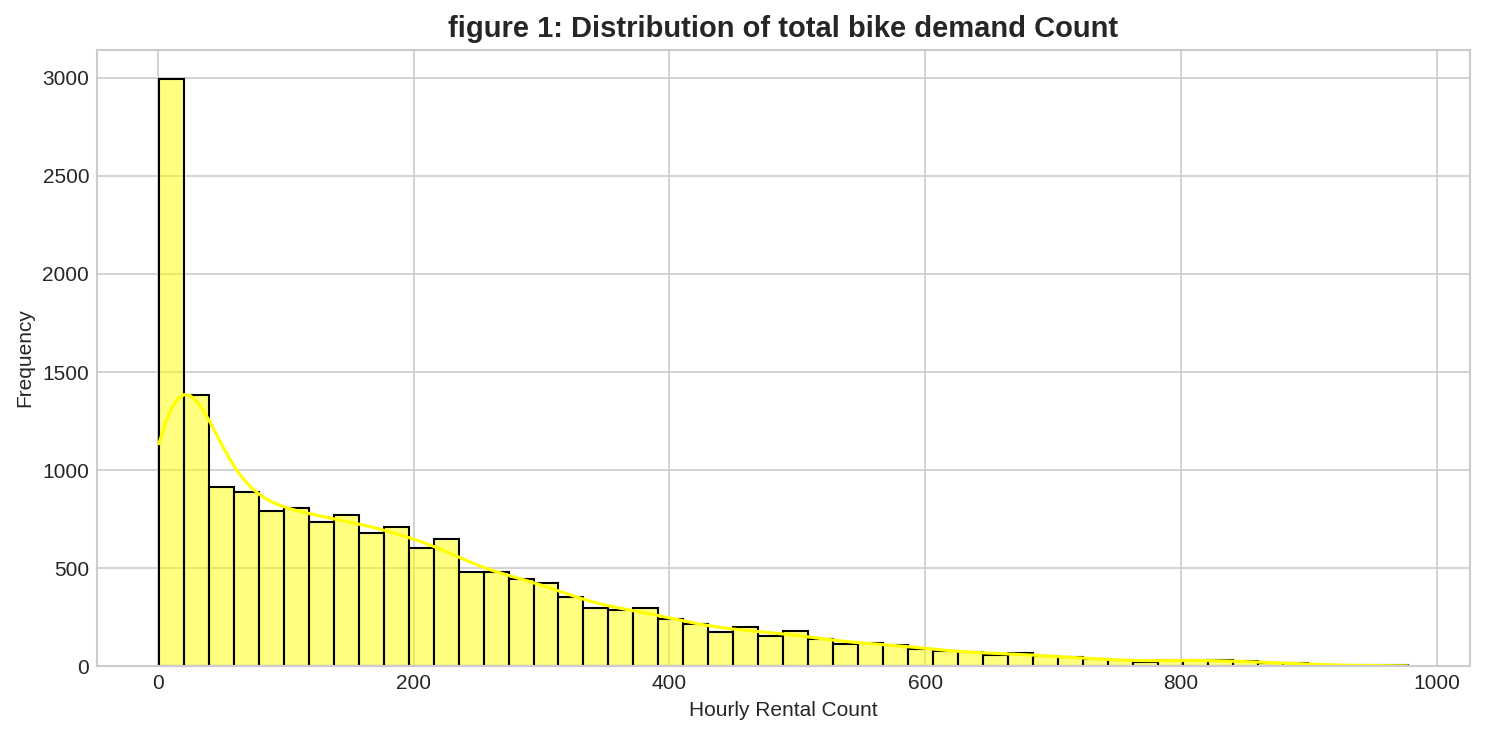

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig_params = {'figsize': (10,5), 'dpi': 150}

plt.figure(**fig_params)
sns.histplot(df['cnt'], kde=True, bins=50, color='yellow')
plt.title('figure 1: Distribution of total bike demand Count', fontsize =14, fontweight='bold')
plt.xlabel('Hourly Rental Count')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show

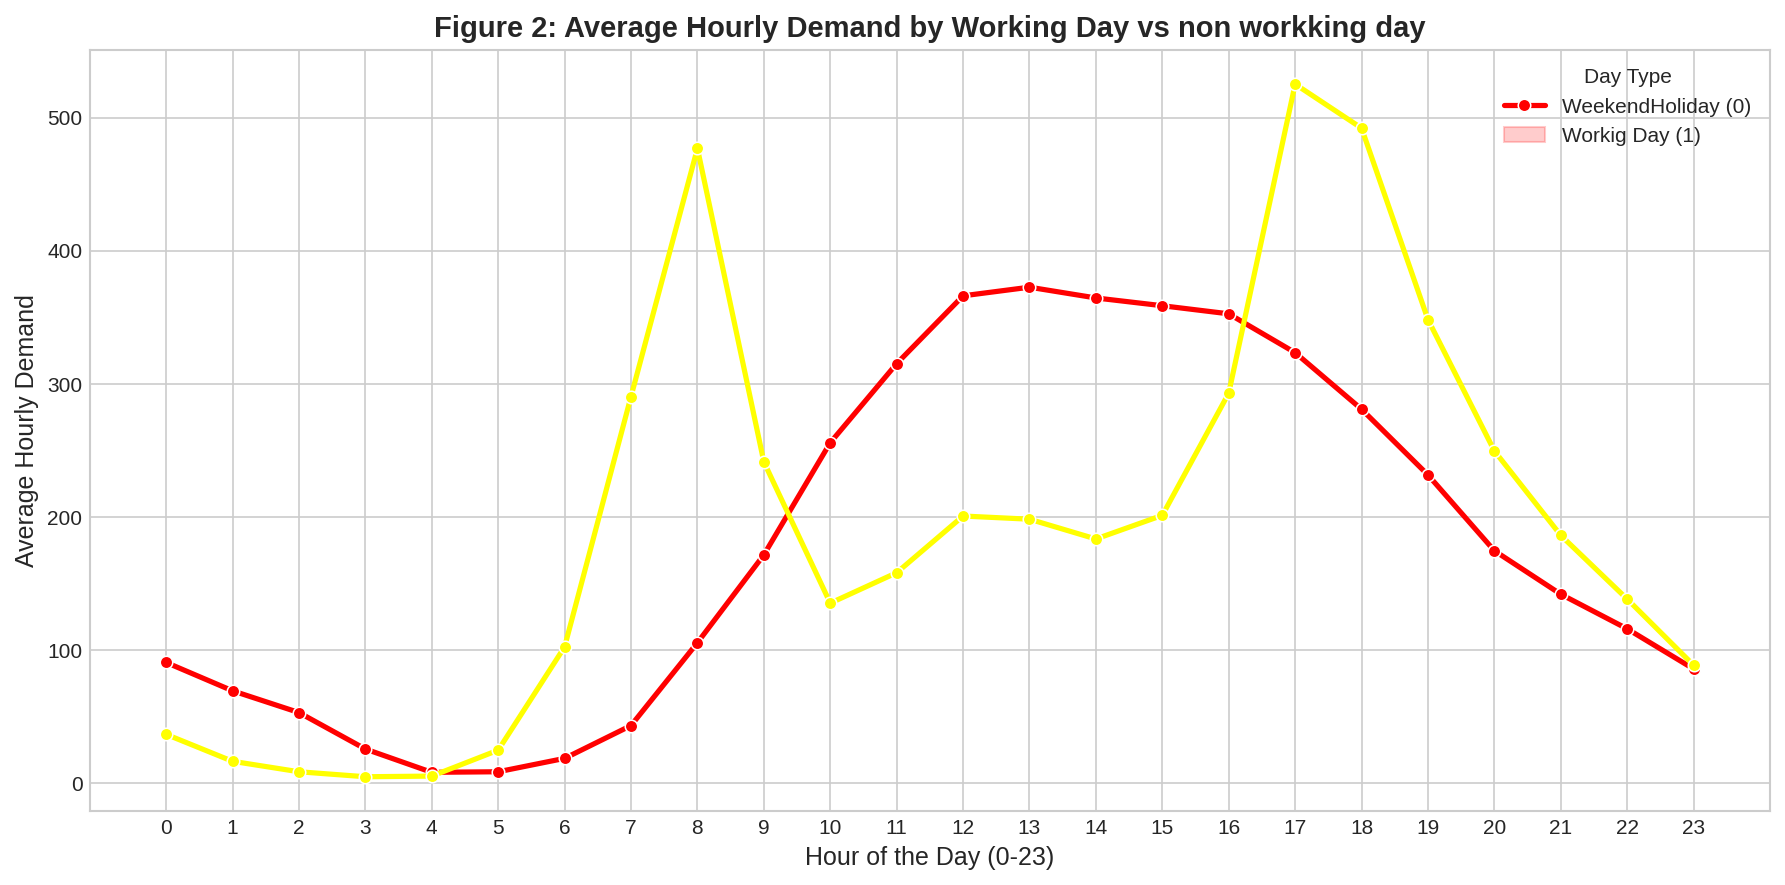

In [4]:
plt.figure(figsize=(12,6), dpi=150)
hourly_commute =df.groupby(['hr','workingday', ])['cnt'].mean().reset_index()

sns.lineplot(data=hourly_commute, x='hr', y='cnt', hue='workingday', marker ='o', palette={0: 'red', 1: 'yellow'}, linewidth=2.5)

plt.title('Figure 2: Average Hourly Demand by Working Day vs non workking day', fontsize=14, fontweight='bold')
plt.xlabel('Hour of the Day (0-23)', fontsize=12)
plt.ylabel('Average Hourly Demand', fontsize =12)

plt.xticks(range(0,24))
plt.legend(title='Day Type', labels=['WeekendHoliday (0)', 'Workig Day (1)'])
plt.tight_layout()
plt.show()




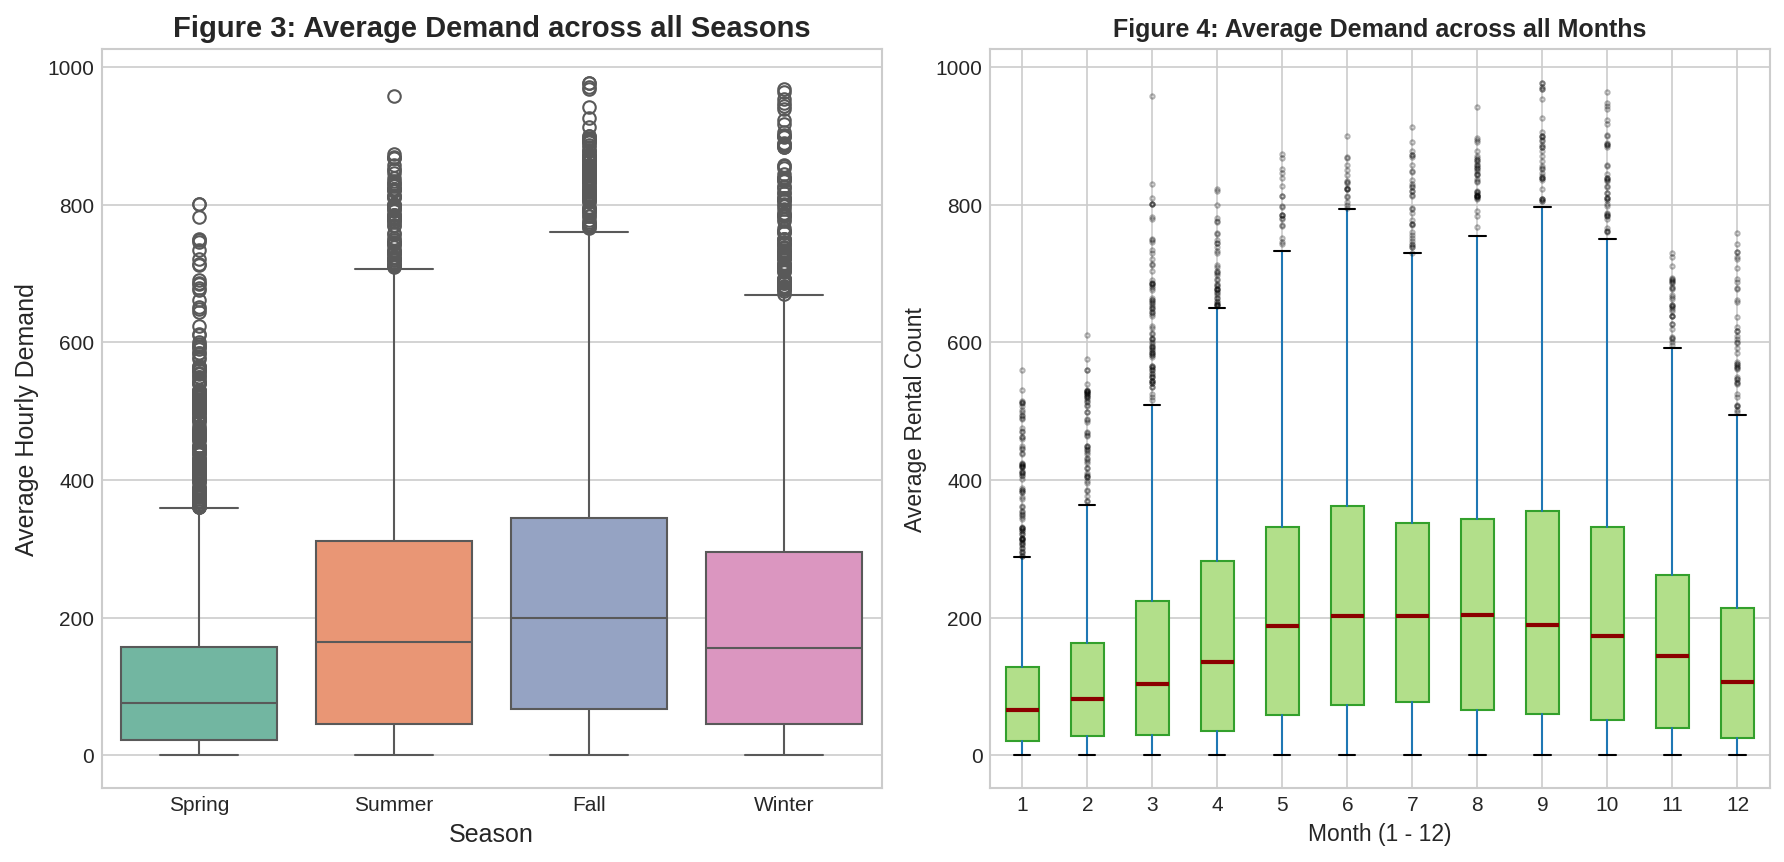

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6), dpi=150)
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
df_plot = df.copy()
df_plot['season_label'] = df_plot['season'].map(season_map)

#sns.boxplot(ax=axes[0], data=df_plot, x='season_label', y='cnt', hue='season_label', palette='Set2', legend=False)
sns.boxplot(
    ax=axes[0],
    data=df_plot,
    x='season_label',
    y='cnt',
    hue='season_label',
    palette='Set2',
    legend=False
)

axes[0].set_title('Figure 3: Average Demand across all Seasons',  fontsize=14, fontweight='bold')
axes[0].set_xlabel('Season', fontsize=12)
axes[0].set_ylabel('Average Hourly Demand', fontsize=12)


# 2. Right Plot: Demand across Months
df.boxplot(
    column='cnt',
    by='mnth',
    ax=axes[1],
    patch_artist=True,
    boxprops=dict(facecolor='#b2df8a', color='#33a02c'),
    medianprops=dict(color='darkred', linewidth=2),
    flierprops=dict(marker='o', markersize=2, alpha=0.3)
)
axes[1].set_title('Figure 4: Average Demand across all Months', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Month (1 - 12)', fontsize=11)
axes[1].set_ylabel('Average Rental Count', fontsize=11)

# Remove the default automatic suptitle generated by pandas boxplot
plt.suptitle('')
plt.tight_layout()
plt.show()



/tmp/ipykernel_707/3339139628.py:14: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(ax=axes[1], data=df_plot, x='weather_label', y='cnt', palette='Reds_d', ci=None)
/tmp/ipykernel_707/3339139628.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], data=df_plot, x='weather_label', y='cnt', palette='Reds_d', ci=None)


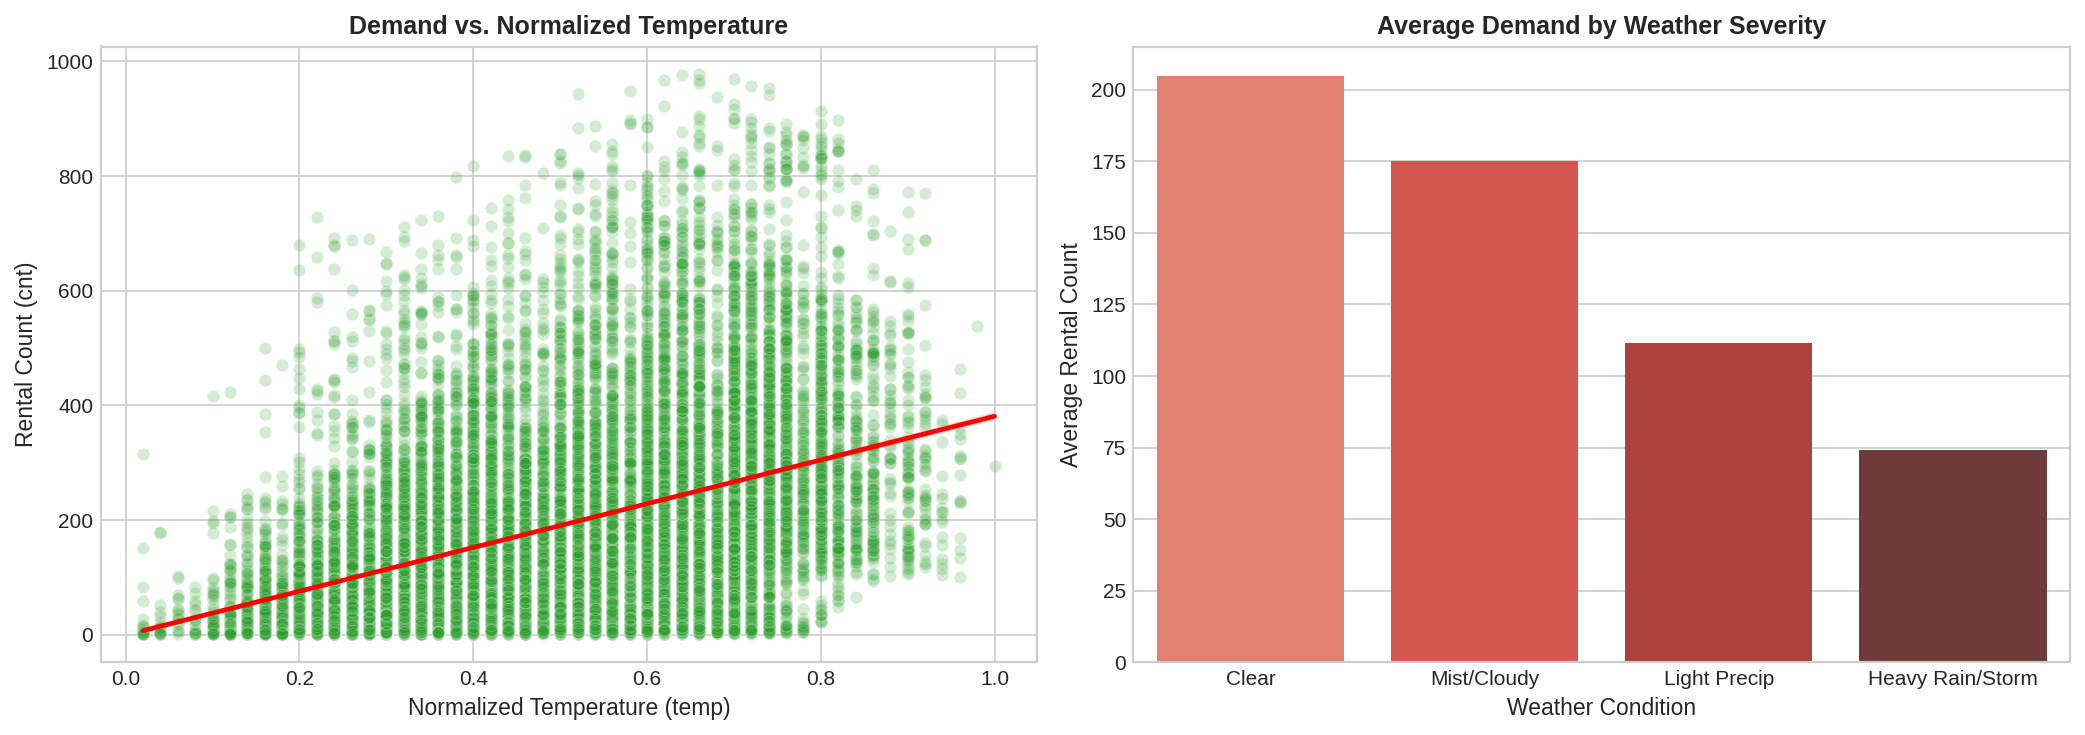

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# Temperature vs. Demand
sns.scatterplot(ax=axes[0], data=df, x='temp', y='cnt', alpha=0.2, color='#2ca02c')
sns.regplot(ax=axes[0], data=df, x='temp', y='cnt', scatter=False, color='red')
axes[0].set_title('Demand vs. Normalized Temperature', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Normalized Temperature (temp)', fontsize=11)
axes[0].set_ylabel('Rental Count (cnt)', fontsize=11)

# Weather Situation (1: Clear, 2: Mist, 3: Light Rain/Snow, 4: Heavy Rain/Storm)
weather_labels = {1: 'Clear', 2: 'Mist/Cloudy', 3: 'Light Precip', 4: 'Heavy Rain/Storm'}
df_plot['weather_label'] = df_plot['weathersit'].map(weather_labels)

sns.barplot(ax=axes[1], data=df_plot, x='weather_label', y='cnt', palette='Reds_d', ci=None)
axes[1].set_title('Average Demand by Weather Severity', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Weather Condition', fontsize=11)
axes[1].set_ylabel('Average Rental Count', fontsize=11)

plt.tight_layout()
plt.show()

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

print("1. Feature/Target Seperation")

X= df_encoded.drop(columns=['cnt'])
y= df_encoded['cnt']

y_log = np.log1p(y)

print(f"Features matrix shape (X), {X.shape}")
print(f"Target vector shape (y), {y.shape}")
print("Feature columns: ", list(X.columns))

print("\n2. Train-Test Split")
X_train, X_test, y_train_log, y_test_log = train_test_split(X,y_log, test_size = 0.2, shuffle =False)

y_test_original = y.iloc[len(X_train):].reset_index(drop =True)

print(f"X_Training set size: {X_train.shape[0]} (80% of data)")
print(f"X_Testing set size: {X_test.shape[0]} (20% of data)")
print(f"y_Training set size: {y_train_log.shape[0]} ")
print(f"y_Testing set size: {y_test_log.shape[0]} ")

#Scaling

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns)

print("\n Model Training")

model = LinearRegression()
model.fit(X_train_scaled, y_train_log)

print("\n Model Trained")
print(f"Intercept (beta_0): {model.intercept_:4f}")
print(f"Number of Coefficients: {len(model.coef_)}")

print("\n Model predictions")

y_pred_log = model.predict(X_test_scaled)
y_pred_actual = np.expm1(y_pred_log)

a




1. Feature/Target Seperation
Features matrix shape (X), (17379, 22)
Target vector shape (y), (17379,)
Feature columns:  ['yr', 'holiday', 'workingday', 'temp', 'hum', 'windspeed', 'hr_sin', 'hr_cos', 'mnth_sin', 'mnth_cos', 'season_2', 'season_3', 'season_4', 'weekday_1', 'weekday_2', 'weekday_3', 'weekday_4', 'weekday_5', 'weekday_6', 'weathersit_2', 'weathersit_3', 'weathersit_4']

2. Train-Test Split
X_Training set size: 13903 (80% of data)
X_Testing set size: 3476 (20% of data)
y_Training set size: 13903 
y_Testing set size: 3476 

 Model Training

 Model Trained
Intercept (beta_0): 4.498742
Number of Coefficients: 22

 Model predictions


,Actual,Predicted Demand,Predicted Demand (Integer),Absolute Error
0,283,465.6,466,182.6
1,253,573.1,573,320.1
2,261,697.0,697,436.0
3,306,781.7,782,475.7
4,445,349.5,350,95.5
5,868,582.1,582,285.9
6,814,454.4,454,359.6
7,610,345.4,345,264.6
8,448,241.0,241,207.0
9,317,170.6,171,146.4


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate regression evaluation metrics on the original scale
mae = mean_absolute_error(y_test_original, y_pred_actual)
mse = mean_squared_error(y_test_original, y_pred_actual)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_original, y_pred_actual)

print("=== Regression Model Evaluation Metrics ===")
print(f"Mean Absolute Error (MAE):     {mae:.2f} (average rental count prediction error)")
print(f"Mean Squared Error (MSE):       {mse:.2f}")
print(f"Root Mean Squared Error (RMSE):  {rmse:.2f}")
print(f"R-squared (R2) Score:           {r2:.4f} (proportion of variance explained)")

=== Regression Model Evaluation Metrics ===
Mean Absolute Error (MAE):     125.74 (average rental count prediction error)
Mean Squared Error (MSE):       34923.55
Root Mean Squared Error (RMSE):  186.88
R-squared (R2) Score:           0.2816 (proportion of variance explained)


Threshold used (median demand): 130.0 rides

Classification Accuracy: 83.3429%

=== Classification Report ===
              precision    recall  f1-score   support

  Low Demand       0.71      0.93      0.81      1299
 High Demand       0.95      0.78      0.85      2177

    accuracy                           0.83      3476
   macro avg       0.83      0.85      0.83      3476
weighted avg       0.86      0.83      0.84      3476



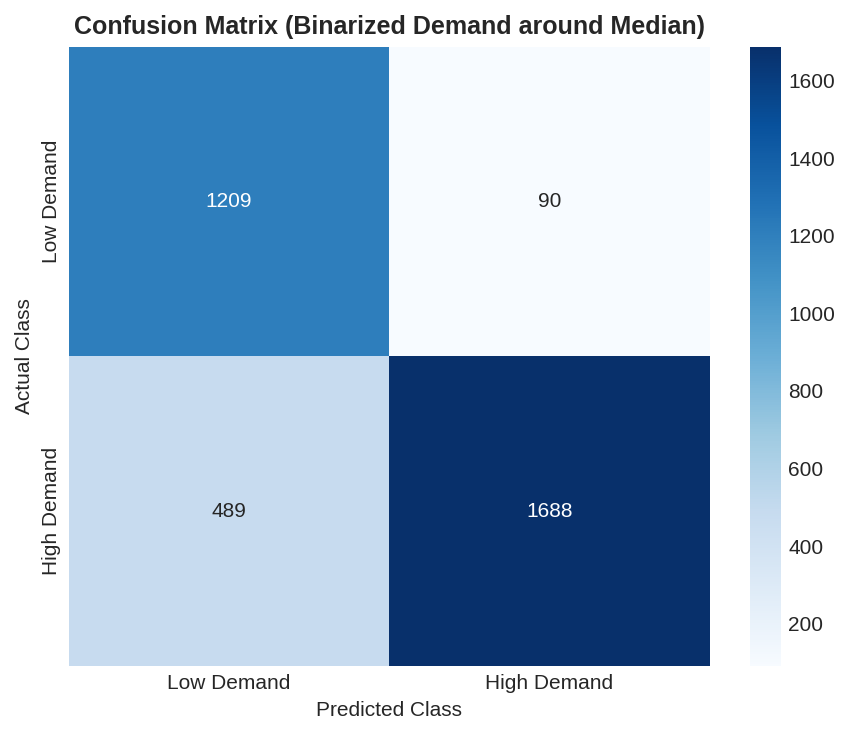

In [14]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Define a threshold to convert regression to classification (using median of training target)
threshold = np.expm1(y_train_log).median()

# 2. Binarize actual test values and predictions
y_test_class = (y_test_original > threshold).astype(int)
y_pred_class = (y_pred_actual > threshold).astype(int)

# 3. Calculate metrics
accuracy = accuracy_score(y_test_class, y_pred_class)
cm = confusion_matrix(y_test_class, y_pred_class)

print(f"Threshold used (median demand): {threshold:.1f} rides\n")
print(f"Classification Accuracy: {accuracy:.4%}\n")
print("=== Classification Report ===")
print(classification_report(y_test_class, y_pred_class, target_names=['Low Demand', 'High Demand']))

# 4. Plot Confusion Matrix
plt.figure(figsize=(6, 5), dpi=150)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low Demand', 'High Demand'],
            yticklabels=['Low Demand', 'High Demand'])
plt.title('Confusion Matrix (Binarized Demand around Median)', fontsize=12, fontweight='bold')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.tight_layout()
plt.show()

In [15]:
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Capture Commuter Peaks (Dummy hours or higher harmonics)
# Standard one-hot encoding for hour captures the distinct 8 AM and 5 PM rush hours directly
df_eng = pd.get_dummies(df.drop(columns=['instant', 'dteday', 'casual', 'registered', 'atemp']),
                        columns=['season', 'weathersit', 'weekday', 'hr', 'mnth'],
                        drop_first=True, dtype=int)

# 2. Add Rush Hour Interaction with Working Day
rush_hours = [7, 8, 9, 17, 18, 19]
df_eng['rush_hour_commute'] = ((df['workingday'] == 1) & (df['hr'].isin(rush_hours))).astype(int)

# 3. Train/Test Split (Chronological 80/20)
X = df_eng.drop(columns=['cnt'])
y = df_eng['cnt']

split_idx = int(len(df_eng) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# 4. Fit directly with Ridge to manage the expanded feature space
model = Ridge(alpha=10.0)
model.fit(X_train, y_train)
y_pred = np.clip(model.predict(X_test), 0, None)  # Enforce non-negative counts

# 5. Evaluate
print(f"MAE:  {mean_absolute_error(y_test, y_pred):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.2f}")
print(f"R²:   {r2_score(y_test, y_pred):.4f}")

MAE:  88.92
RMSE: 117.95
R²:   0.7138


       PHASE 6: MODEL EVALUATION METRICS     
Mean Absolute Error (MAE):       88.92
Mean Squared Error (MSE):        13911.68
Root Mean Squared Error (RMSE):  117.95
R-squared (R²) Score:            0.7138


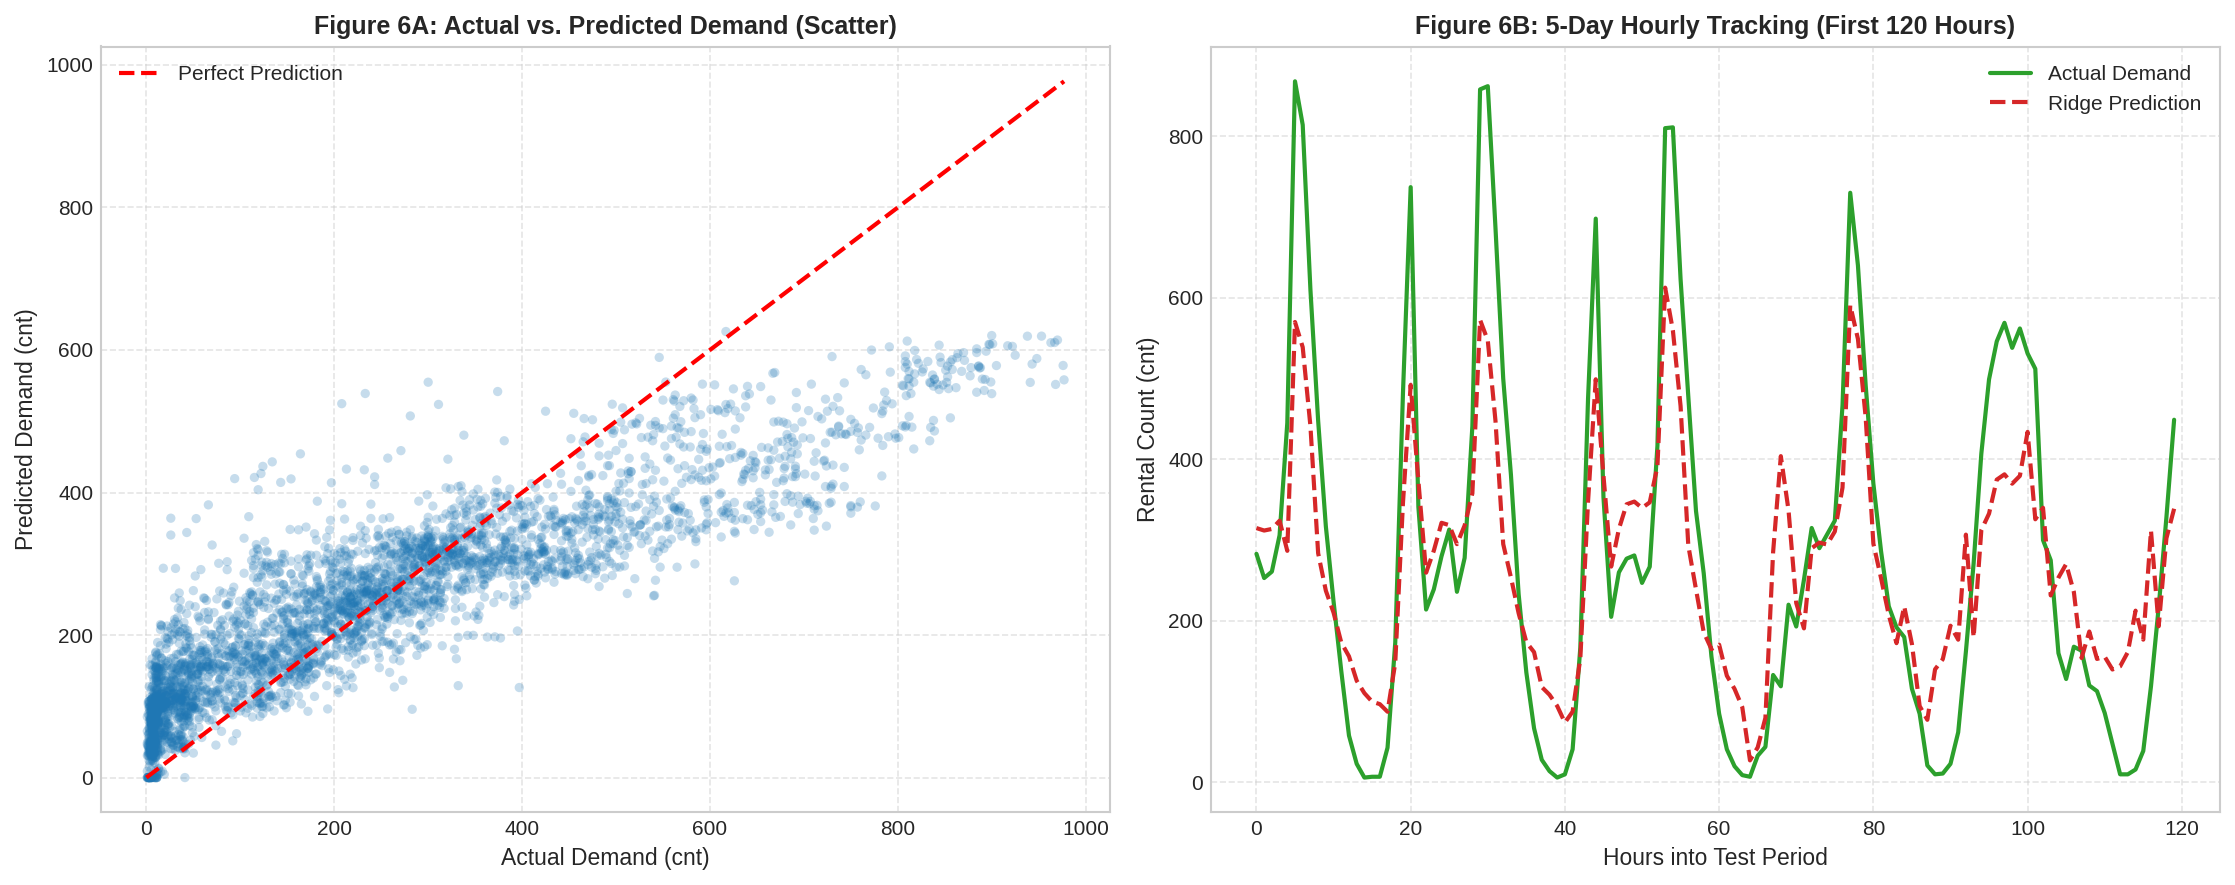

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Compute Full Metrics Suite
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("="*45)
print("       PHASE 6: MODEL EVALUATION METRICS     ")
print("="*45)
print(f"Mean Absolute Error (MAE):       {mae:.2f}")
print(f"Mean Squared Error (MSE):        {mse:.2f}")
print(f"Root Mean Squared Error (RMSE):  {rmse:.2f}")
print(f"R-squared (R²) Score:            {r2:.4f}")
print("="*45)

# 2. Actual vs. Predicted Visualizations
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=150)

# Subplot A: Direct Scatter Plot with 45-degree Reference Line
axes[0].scatter(y_test, y_pred, alpha=0.25, color='#1f77b4', edgecolors='none', s=20)
axes[0].plot([0, y_test.max()], [0, y_test.max()], 'r--', lw=2, label='Perfect Prediction')
axes[0].set_title('Figure 6A: Actual vs. Predicted Demand (Scatter)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Actual Demand (cnt)', fontsize=11)
axes[0].set_ylabel('Predicted Demand (cnt)', fontsize=11)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot B: Time-Series Zoom (First 120 hours / 5 days of Test Set)
sample_hours = 120
axes[1].plot(y_test.values[:sample_hours], label='Actual Demand', color='#2ca02c', lw=2)
axes[1].plot(y_pred[:sample_hours], label='Ridge Prediction', color='#d62728', linestyle='--', lw=2)
axes[1].set_title(f'Figure 6B: 5-Day Hourly Tracking (First {sample_hours} Hours)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Hours into Test Period', fontsize=11)
axes[1].set_ylabel('Rental Count (cnt)', fontsize=11)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [19]:
import numpy as np
import pandas as pd

# Rebuilding comparison_df using the correct, updated Ridge predictions (y_pred) and actuals (y_test)
comparison_df = pd.DataFrame({
    'Actual Demand': y_test.values[:10],
    'Predicted Demand (Ridge)': np.round(y_pred[:10], 1),
    'Predicted (Integer)': np.round(y_pred[:10]).astype(int),
    'Absolute Error': np.round(np.abs(y_test.values[:10] - y_pred[:10]), 1)
})

display(comparison_df)

,Actual Demand,Predicted Demand (Ridge),Predicted (Integer),Absolute Error
0,283,314.9,315,31.9
1,253,311.8,312,58.8
2,261,313.8,314,52.8
3,306,324.0,324,18.0
4,445,286.7,287,158.3
5,868,570.0,570,298.0
6,814,538.8,539,275.2
7,610,441.1,441,168.9
8,448,283.8,284,164.2
9,317,237.4,237,79.6
